In [2]:
%load_ext autoreload 
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# 1. Imports

In [3]:

from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
from astropy.io import fits
from astropy.table import Table
import numpy as np
from datetime import datetime
from scipy.optimize import brentq
from tqdm.notebook import tqdm
import json, pickle
import os
from mpdaf.obj import Cube


# 0. Download mock cubes with noise

download ired_cubes.zip available at [link](https://filesender.renater.fr/?s=download&token=7de5e051-2526-48dd-b0bb-67ed96816cb9)

cp ired_cubes.zip {path_to_data}

unzip ired_cubes.zip

# 1. define path to data

files with empty sky(noise) are sampled at 2AA (Low resolution) or 1AA (high-resolution) corresponding to the two concepts

the files `empty` are empty cubes with sky noise and RON+dark

the files `sky` have the full sky flux and RON+dark for two exposures A & B which can be used to perform sky-subtraction

the cubes are 30x30 in size (spaxels)


In [4]:
path_to_data = '/home/nbouche/Nextcloud/Instru/irMUSE/redSi_v4/'

os.system(f'ls {path_to_data}/*2A*')


/home/nbouche/Nextcloud/Instru/irMUSE/redSi_v4//iredmuse_zJ_2AA_1x1200_6ron_72_dark_empty_A_finalvar.fits
/home/nbouche/Nextcloud/Instru/irMUSE/redSi_v4//iredmuse_zJ_2AA_1x300_6ron_72_dark_empty_A_finalvar.fits
/home/nbouche/Nextcloud/Instru/irMUSE/redSi_v4//iredmuse_zJ_2AA_1x600_6ron_72_dark_empty_A_finalvar.fits
/home/nbouche/Nextcloud/Instru/irMUSE/redSi_v4//iredmuse_zJ_2AA_1x900_6ron_72_dark_empty_A_finalvar.fits
/home/nbouche/Nextcloud/Instru/irMUSE/redSi_v4//iredmuse_zJ_2AA_1x900_6ron_72_dark_empty_B_finalvar.fits
/home/nbouche/Nextcloud/Instru/irMUSE/redSi_v4//iredmuse_zJ_2AA_1x900_6ron_72_dark_sky_A_finalvar.fits
/home/nbouche/Nextcloud/Instru/irMUSE/redSi_v4//iredmuse_zJ_2AA_1x900_6ron_72_dark_sky_B_finalvar.fits


0

In [5]:
os.system(f'ls {path_to_data}/*1A*')


/home/nbouche/Nextcloud/Instru/irMUSE/redSi_v4//iredmuse_zJ_1AA_1x900_6ron_72_dark_empty_A_finalvar.fits
/home/nbouche/Nextcloud/Instru/irMUSE/redSi_v4//iredmuse_zJ_1AA_1x900_6ron_72_dark_empty_B_finalvar.fits
/home/nbouche/Nextcloud/Instru/irMUSE/redSi_v4//iredmuse_zJ_1AA_1x900_6ron_72_dark_sky_A_finalvar.fits
/home/nbouche/Nextcloud/Instru/irMUSE/redSi_v4//iredmuse_zJ_1AA_1x900_6ron_72_dark_sky_B_finalvar.fits


0

## set sampling

In [12]:
samp=2

if samp==1:
    sampling=1 #AA
elif samp==2:
    sampling=2 #AA
else:
    raise ValueError

In [13]:

filename = f"{path_to_data}/iredmuse_zJ_{sampling:0d}AA_1x900_6ron_72_dark_empty_B_finalvar.fits"

empty=fits.open(filename)
empty.info()
empty[1].header

Filename: /home/nbouche/Nextcloud/Instru/irMUSE/redSi_v4//iredmuse_zJ_2AA_1x900_6ron_72_dark_empty_B_finalvar.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      59   ()      
  1  DATA          1 ImageHDU        29   (30, 30, 2000)   float32   
  2  STAT          1 ImageHDU        29   (30, 30, 2000)   float32   


XTENSION= 'IMAGE   '           / Image extension                                
BITPIX  =                  -32 / array data type                                
NAXIS   =                    3 / number of array dimensions                     
NAXIS1  =                   30                                                  
NAXIS2  =                   30                                                  
NAXIS3  =                 2000                                                  
PCOUNT  =                    0 / number of parameters                           
GCOUNT  =                    1 / number of groups                               
WCSAXES =                    3 / Number of coordinate axes                      
CRPIX1  =                 15.0 / Pixel coordinate of reference point            
CRPIX2  =                 15.0 / Pixel coordinate of reference point            
CD1_1   =  6.1111111111111E-05 / Coordinate transformation matrix element       
CD2_2   =  6.1111111111111E-

In [14]:

cube=Cube(filename)
cube.shape

if samp==1:
    nz=cube.shape[0]//2+65
elif samp==2:
    nz=cube.shape[0]//2-25
else:
    raise ValueError
    


In [15]:
skyname_A=f'{path_to_data}/iredmuse_zJ_{sampling:0d}AA_1x900_6ron_72_dark_sky_A_finalvar.fits'
skyname_B=f'{path_to_data}/iredmuse_zJ_{sampling:0d}AA_1x900_6ron_72_dark_sky_B_finalvar.fits'

sky_A=Cube(skyname_A)
sky_B=Cube(skyname_B)


# 2. set noise cube

In [16]:

noise_cube=cube[nz-25:nz+25,:,:]

sky_A=sky_A[nz-25:nz+25,:,:]
sky_B=sky_B[nz-25:nz+25,:,:]


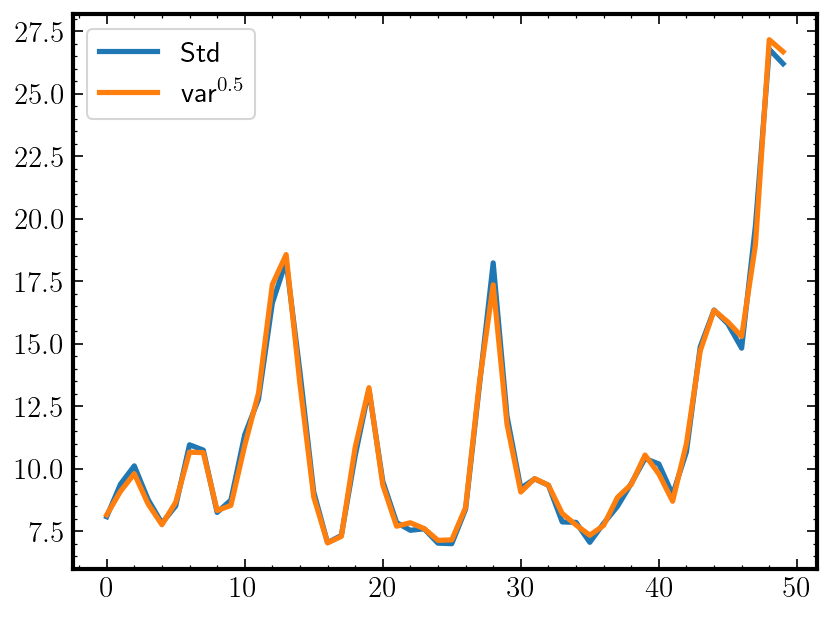

In [17]:
plt.plot(np.std(noise_cube.data,axis=(1,2)),label='Std')
plt.plot(np.mean(noise_cube.var**0.5,axis=(1,2)),label='var$^{0.5}$')
plt.legend()

# 3. Create Source with galpak3d

Note1 the mock data should be in #erg/s/cm2/AA since the cube has these units

Note2 the noise empty cube is for 900 or 1200s, so 

- either scale the flux by sqrt(EXPTIME/900) for a quick look 

- or move the source around and co-add

In [18]:
import galpak

INFO:GalPaK: Plots:bottleneck (optional) not installed, performances will be degraded
INFO:root: bottleneck (optional) not installed, performances will be degraded
INFO:root: PyFFTW (optional) not installed, performances will be degraded
INFO:root:Found MPDAF version 3.6
INFO:root:Found PyMultinest version 2.12
INFO:root:corner (optional) not installed, corner plots will be disabled
INFO:GalPaK: Running galpak 2.1.12.dev23+g3567fb8c6.d20260601


In [19]:
model=galpak.ModelSersic(flux_profile='sersic',rotation_curve='tanh',redshift=1)
p=model.Parameters()
p.flux=6000/sampling #erg/s/cm2/AA 3e-16 and 2AA sampling
p.sersic_n=1.0
p.inclination=60
p.pa=30
p.maximum_velocity=120
p.turnover_radius=1
p.velocity_dispersion=40.
p.radius=3.
p.x=p.y=15
p.z=noise_cube.shape[0]//2
p

INFO:GalPaK: DiskModel:Astropy: Parameter planck15 is not available
 Please use one of ('WMAP1', 'WMAP3', 'WMAP5', 'WMAP7', 'WMAP9', 'Planck13', 'Planck15', 'Planck18') 
Will be uing astropy.cosmology Planck15 as default



Model Parameters : value (unit)
    x: 15.00 (pixel)
    y: 15.00 (pixel)
    z: 25.000000 (pixel)
    flux: 3.00e+03 (same units as the input Cube)
    radius: 3.00 (pixel)
    sersic_n: 1.00
    inclination: 60.0 (deg)
    pa:  30.0 (deg)
    turnover_radius: 1.00 (pixel)
    maximum_velocity: 120.00 (km/s)
    velocity_dispersion: 30.00 (km/s)

In [20]:
psf=galpak.MoffatPointSpreadFunction(fwhm=0.6,pa=0,ba=1,beta=2.5)
print(psf)

[PSF] :
  type = Moffat
  fwhm         = 0.6 arcsec
  alpha        = 0.5307383219736449 arcsec
  beta         = 2.5  
  pa           = 0 °
  ba           = 1


In [21]:
lsf=galpak.GaussianLineSpreadFunction(fwhm=2.2*sampling)
print(lsf)

[LSF] :
  type = Gaussian
  fwhm = 4.4  Undef 



In [22]:
redmuse=galpak.Generic(psf=psf,lsf=lsf)
gpk=galpak.GalPaK3D(noise_cube,model=model,instrument=redmuse)


INFO:GalPaK:Provided Cube is a mpdaf Cube object
INFO:GalPak: HyperCube:Both CD3_3 and CDELT3 are present 
 will use CDELT3 !
INFO:GalPak: HyperCube:Patching the header with cards provided
INFO:GalPaK:Replacing 0s in the variance cube by 1e12
INFO:GalPaK:Setting up with the following setup :
[INSTRUMENT] :
  type = Generic
  pixscale = 0.21999999999999958 arcsec

[PSF] :
  type = Moffat
  fwhm         = 0.6 arcsec
  alpha        = 0.5307383219736449 arcsec
  beta         = 2.5  
  pa           = 0 °
  ba           = 1
[LSF] :
  type = Gaussian
  fwhm = 4.4  Angstrom 

cube_xy_step   = 0.21999999999999958 arcsec
cube_z_step    = 2.0 Angstrom

cube z_step_kms = 53.34281650071124 km/s  at 11248.0 Angstrom


INFO:GalPaK:Init boundaries from model 'ModelSersic'
INFO:GalPaK:Initial flux is 4.75e+02
INFO:GalPaK:Setting up the model : ModelSersic
INFO:GalPaK:Model setup :
[MODEL] :
  type = ModelSersic
  flux_profile = sersic 
  rotation_curve = tanh 
  thickness_profile = gaussian 
  dispersi

/home/nbouche/Python_git/galpak/src/galpak/model_class.py:384: RuntimeWarning: underflow encountered in exp
  tmp_cube = np.exp(-nz**2. / 2. / (hz)**2.) / (np.sqrt(2*np.pi)*hz)
/home/nbouche/Python_git/galpak/src/galpak/model_class.py:384: RuntimeWarning: underflow encountered in divide
  tmp_cube = np.exp(-nz**2. / 2. / (hz)**2.) / (np.sqrt(2*np.pi)*hz)
/home/nbouche/Python_git/galpak/src/galpak/model_class.py:408: RuntimeWarning: underflow encountered in multiply
  return flux_cube * tmp_cube
/home/nbouche/Python_git/galpak/src/galpak/model_class.py:606: RuntimeWarning: underflow encountered in divide
  flux_cube =  flux_cube / total
/home/nbouche/Python_git/galpak/src/galpak/model_class.py:612: RuntimeWarning: underflow encountered in square
  bad = (flux_map**2 == 0)
/home/nbouche/Python_git/galpak/src/galpak/model_class.py:614: RuntimeWarning: underflow encountered in multiply
  vz_map = bn.nansum(vz_cube * flux_cube / flux_map, 0)
/home/nbouche/Python_git/galpak/src/galpak/model_

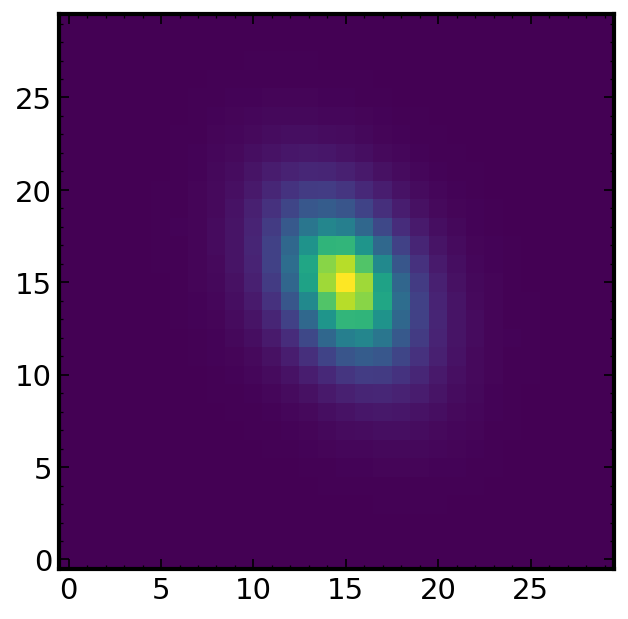

In [23]:
cube_clean = gpk.create_clean_cube(p,shape=noise_cube.shape)
cube_conv =gpk.create_convolved_cube(p,shape=noise_cube.shape)
plt.imshow(cube_conv.data.sum(0))

In [24]:
noise_cube.shape

(50, 30, 30)

In [25]:
cube_conv.shape

(50, 30, 30)

In [26]:
cube_with_noise=galpak.HyperCube(cube_conv.data+noise_cube.data,variance=noise_cube.var,header=noise_cube.data_header)

INFO:GalPak: HyperCube:Both CD3_3 and CDELT3 are present 
 will use CDELT3 !


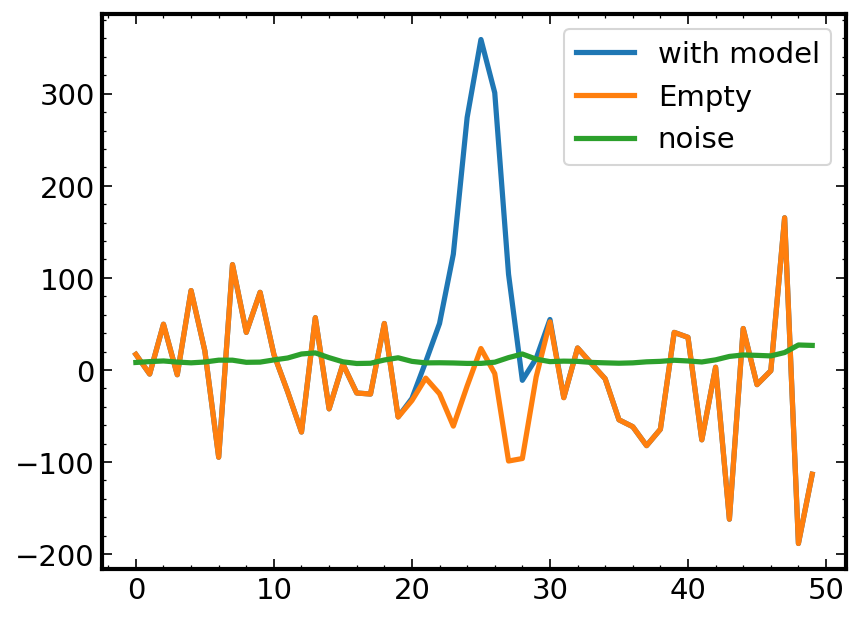

In [27]:
dx=3
plt.plot(cube_with_noise.data[:,15-dx:15+dx,15-dx:15+dx].sum((1,2)),label='with model')
plt.plot(noise_cube.data[:,15-dx:15+dx,15-dx:15+dx].sum((1,2)),label='Empty')
plt.plot((noise_cube.var**0.5).mean(axis=(1,2)),label='noise')
plt.legend()

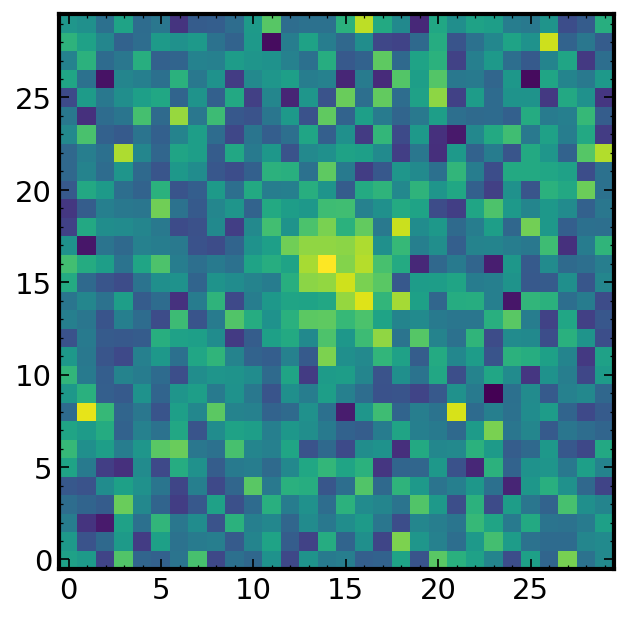

In [28]:
plt.imshow(cube_with_noise.data[int(p.z)-2:int(p.z)+2,:,:].sum(axis=(0)))

## refit with Galpak

INFO:GalPaK:Provided cube is a HyperSpectral Object
INFO:GalPak: HyperCube:Patching the header with cards provided
INFO:GalPaK:Replacing 0s in the variance cube by 1e12
INFO:GalPaK:Setting up with the following setup :
[INSTRUMENT] :
  type = Generic
  pixscale = 0.21999999999999958 arcsec

[PSF] :
  type = Moffat
  fwhm         = 0.6 arcsec
  alpha        = 0.5307383219736449 arcsec
  beta         = 2.5  
  pa           = 0 °
  ba           = 1
[LSF] :
  type = Gaussian
  fwhm = 4.4  Angstrom 

cube_xy_step   = 0.21999999999999958 arcsec
cube_z_step    = 2.0 Angstrom

cube z_step_kms = 53.34281650071124 km/s  at 11248.0 Angstrom


INFO:GalPaK:Init boundaries from model 'ModelSersic'
INFO:GalPaK:Initial flux is 3.47e+03
INFO:GalPaK:Setting up the model : ModelSersic
INFO:GalPaK:Model setup :
[MODEL] :
  type = ModelSersic
  flux_profile = sersic 
  rotation_curve = tanh 
  thickness_profile = gaussian 
  dispersion_profile = thick 
  line = None 
  aspect = None 
  redshift = 1 
  pixs

 *****************************************************
 MultiNest v3.10
 Copyright Farhan Feroz & Mike Hobson
 Release Jul 2015

 no. of live points =  200
 dimensionality =   11
 *****************************************************
 Starting MultiNest
 generating live points
 live points generated, starting sampling
Acceptance Rate:                        0.976562
Replacements:                                250
Total Samples:                               256
Nested Sampling ln(Z):             -22913.436824
Importance Nested Sampling ln(Z):  -22645.476633 +/-  0.998045
Acceptance Rate:                        0.923077
Replacements:                                300
Total Samples:                               325
Nested Sampling ln(Z):             -22817.780391
Importance Nested Sampling ln(Z):  -22645.703016 +/-  0.986327
Acceptance Rate:                        0.899743
Replacements:                                350
Total Samples:                               389
Nested Sampling

INFO:GalPaK:self.chain : full Markov chain
INFO:GalPaK:Extracting best parameters (medians) from chain
INFO:GalPaK:Setting 95 percentiles 
INFO:GalPaK:self.galaxy : fittest parameters : ± stdev (unit)	 [Confidence Interval]
    x: 14.75 ± 0.19 (pixel)	 CI 95%: [14.41, 15.16]  
    y: 15.21 ± 0.25 (pixel)	 CI 95%: [14.69, 15.63]  
    z: 24.791904 ± 0.164590 (pixel)	 CI 95%: [24.507958, 25.121815]  
    flux: 2.55e+03 ± 2.57e+02 (same units as the input Cube)	 CI 95%: [2.07e+03, 3.05e+03]  
    radius: 3.52 ± 0.76 (pixel)	 CI 95%: [2.61, 5.47]  
    sersic_n: 1.08 ± 0.80	 CI 95%: [0.47, 3.52]  
    inclination: 72.2 ±  7.0 (deg)	 CI 95%: [57.2, 86.1]  
    pa:  29.6 ±   4.7 (deg)	 CI 95%: [ 19.8,  38.3]  
    turnover_radius: 2.97 ± 1.03 (pixel)	 CI 95%: [1.09, 5.05]  
    maximum_velocity: 137.79 ±  23.26 (km/s)	 CI 95%: [ 97.30, 186.66]  
    velocity_dispersion: 12.54 ± 9.64 (km/s)	 CI 95%: [0.63, 35.65]  

INFO:GalPaK:self.stdev : parameters stdev : x=0.19 y=0.25 z=0.164590 flux=2.5

Acceptance Rate:                        0.149113
Replacements:                               4638
Total Samples:                             31104
Nested Sampling ln(Z):             -22607.521597
Importance Nested Sampling ln(Z):  -22610.750775 +/-  0.014593
  analysing data from ./pymulti/out.txt
 ln(ev)=  -22607.384261018378      +/-  0.29261422390182373     
 Total Likelihood Evaluations:        31104
 Sampling finished. Exiting MultiNest


/home/nbouche/Python_git/galpak/src/galpak/plot_utilities.py:190: RuntimeWarning: divide by zero encountered in log10
  ax.plot(np.log10(chain['reduced_chi'][idx] - np.min(chain['reduced_chi'])))


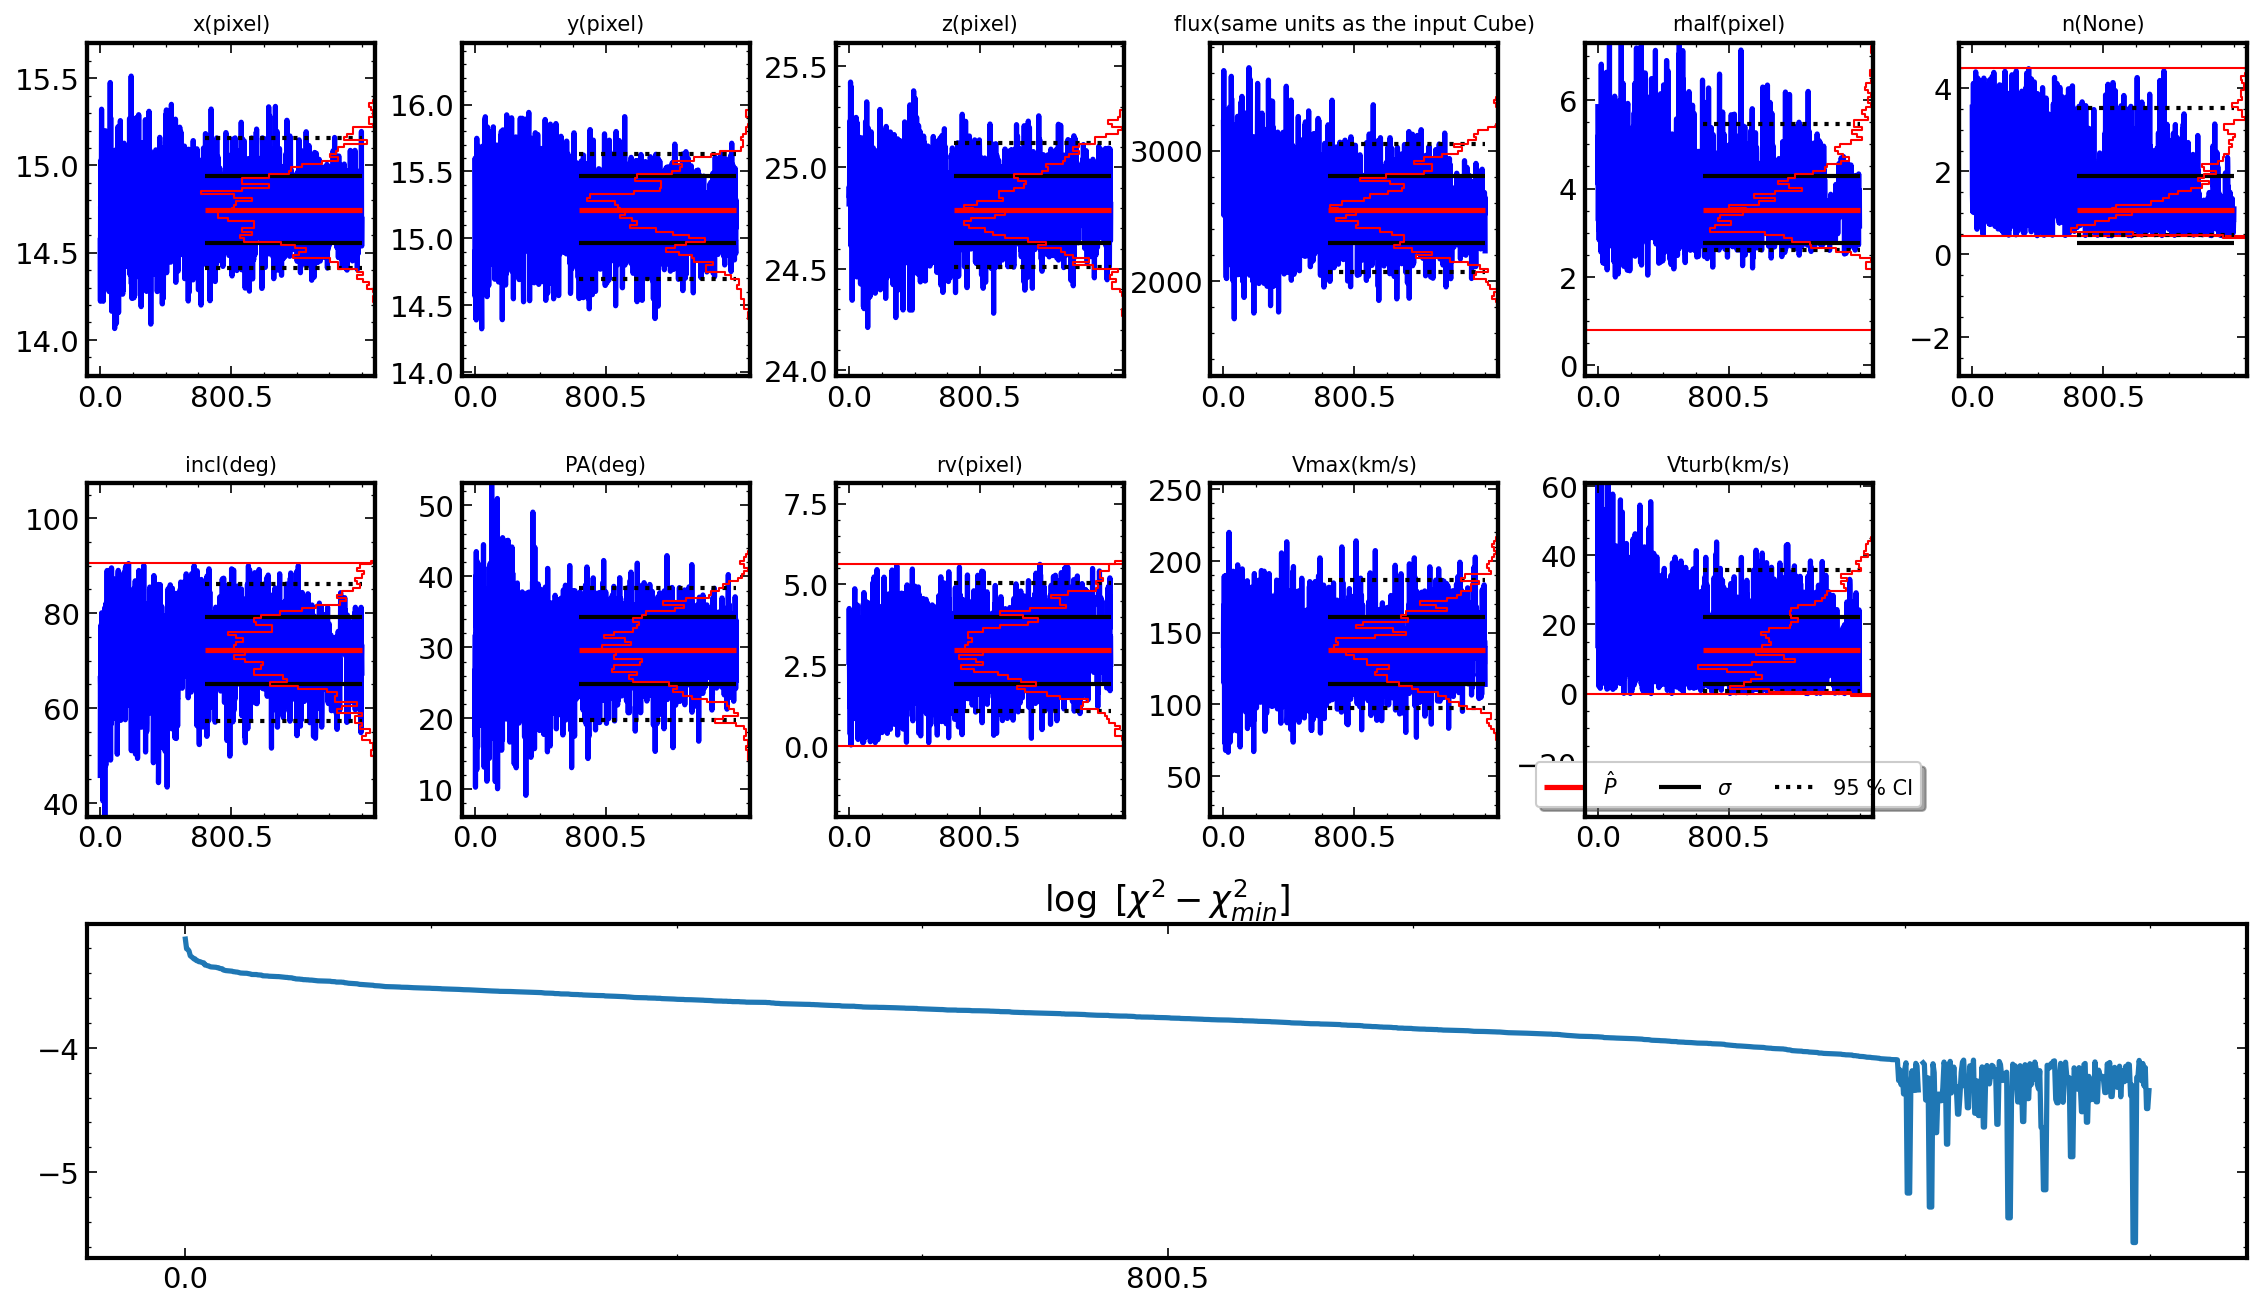

INFO:GalPaK: Plots:Parameter x has converged ? 1.00
INFO:GalPaK: Plots:Parameter y has converged ? 1.00
INFO:GalPaK: Plots:Parameter z has converged ? 1.00
INFO:GalPaK: Plots:Parameter flux has converged ? 1.00
INFO:GalPaK: Plots:Parameter radius has converged ? 1.00
INFO:GalPaK: Plots:Parameter sersic_n has converged ? 1.00
INFO:GalPaK: Plots:Parameter inclination has converged ? 1.00
INFO:GalPaK: Plots:Parameter pa has converged ? 1.00
INFO:GalPaK: Plots:Parameter turnover_radius has converged ? 1.00
INFO:GalPaK: Plots:Parameter maximum_velocity has converged ? 1.00
INFO:GalPaK: Plots:Parameter velocity_dispersion has converged ? 1.00


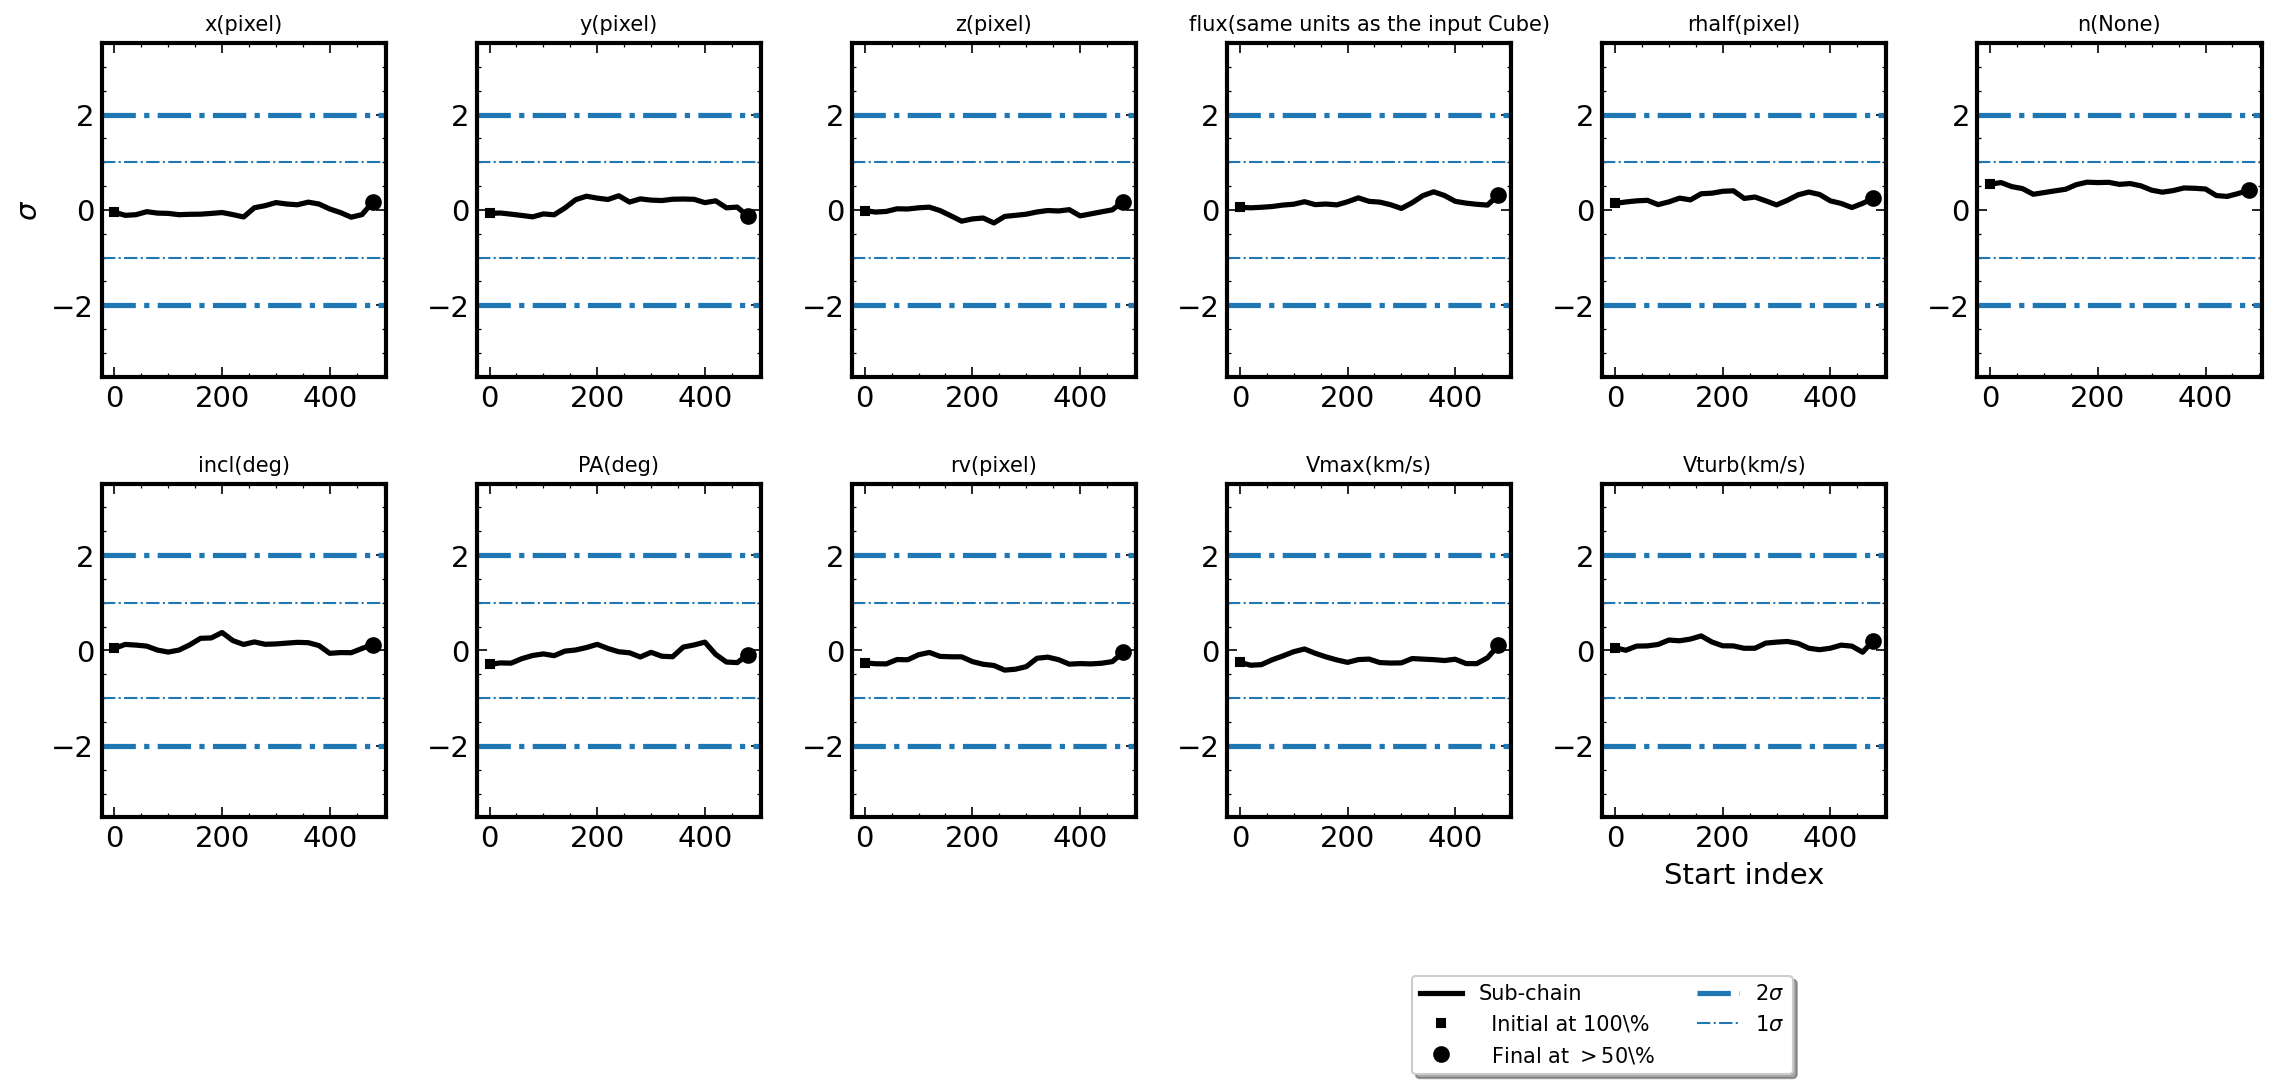

± stdev (unit)	 [Confidence Interval]
    x: 14.75 ± 0.19 (pixel)	 CI 95%: [14.41, 15.16]  
    y: 15.21 ± 0.25 (pixel)	 CI 95%: [14.69, 15.63]  
    z: 24.791904 ± 0.164590 (pixel)	 CI 95%: [24.507958, 25.121815]  
    flux: 2.55e+03 ± 2.57e+02 (same units as the input Cube)	 CI 95%: [2.07e+03, 3.05e+03]  
    radius: 3.52 ± 0.76 (pixel)	 CI 95%: [2.61, 5.47]  
    sersic_n: 1.08 ± 0.80	 CI 95%: [0.47, 3.52]  
    inclination: 72.2 ±  7.0 (deg)	 CI 95%: [57.2, 86.1]  
    pa:  29.6 ±   4.7 (deg)	 CI 95%: [ 19.8,  38.3]  
    turnover_radius: 2.97 ± 1.03 (pixel)	 CI 95%: [1.09, 5.05]  
    maximum_velocity: 137.79 ±  23.26 (km/s)	 CI 95%: [ 97.30, 186.66]  
    velocity_dispersion: 12.54 ± 9.64 (km/s)	 CI 95%: [0.63, 35.65]  

In [33]:
gk=galpak.GalPaK3D(cube_with_noise,instrument=redmuse,model=model)
prior=model.Parameters()
pg=model.Parameters()
prior.turnover_radius=1
pg.turnover_radius=2

gk.run_mcmc(mcmc_method='multinest',gprior_parameters=[prior,pg])


In [34]:
gk.galaxy,p

(± stdev (unit)	 [Confidence Interval]
     x: 14.75 ± 0.19 (pixel)	 CI 95%: [14.41, 15.16]  
     y: 15.21 ± 0.25 (pixel)	 CI 95%: [14.69, 15.63]  
     z: 24.791904 ± 0.164590 (pixel)	 CI 95%: [24.507958, 25.121815]  
     flux: 2.55e+03 ± 2.57e+02 (same units as the input Cube)	 CI 95%: [2.07e+03, 3.05e+03]  
     radius: 3.52 ± 0.76 (pixel)	 CI 95%: [2.61, 5.47]  
     sersic_n: 1.08 ± 0.80	 CI 95%: [0.47, 3.52]  
     inclination: 72.2 ±  7.0 (deg)	 CI 95%: [57.2, 86.1]  
     pa:  29.6 ±   4.7 (deg)	 CI 95%: [ 19.8,  38.3]  
     turnover_radius: 2.97 ± 1.03 (pixel)	 CI 95%: [1.09, 5.05]  
     maximum_velocity: 137.79 ±  23.26 (km/s)	 CI 95%: [ 97.30, 186.66]  
     velocity_dispersion: 12.54 ± 9.64 (km/s)	 CI 95%: [0.63, 35.65]  ,
 
 Model Parameters : value (unit)
     x: 15.00 (pixel)
     y: 15.00 (pixel)
     z: 25.000000 (pixel)
     flux: 3.00e+03 (same units as the input Cube)
     radius: 3.00 (pixel)
     sersic_n: 1.00
     inclination: 60.0 (deg)
     pa:  30.0 (deg)

## Try Skysub

In [ ]:
test=sky_A.data+cube_conv.data-sky_B.data


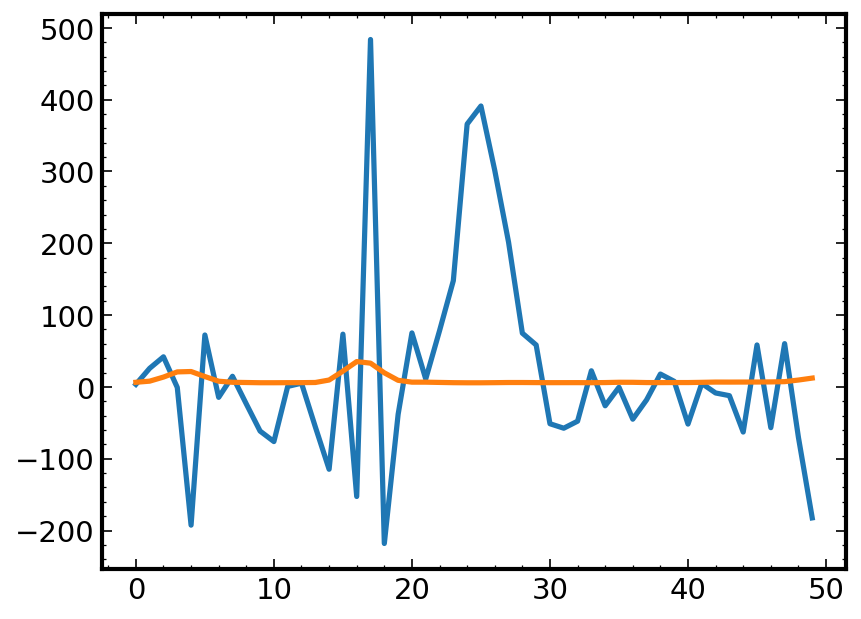

In [262]:
plt.plot(test[:,15-dx:15+dx,15-dx:15+dx].sum((1,2)),label='with model')
plt.plot((noise_cube.var**0.5).mean(axis=(1,2)),label='noise')


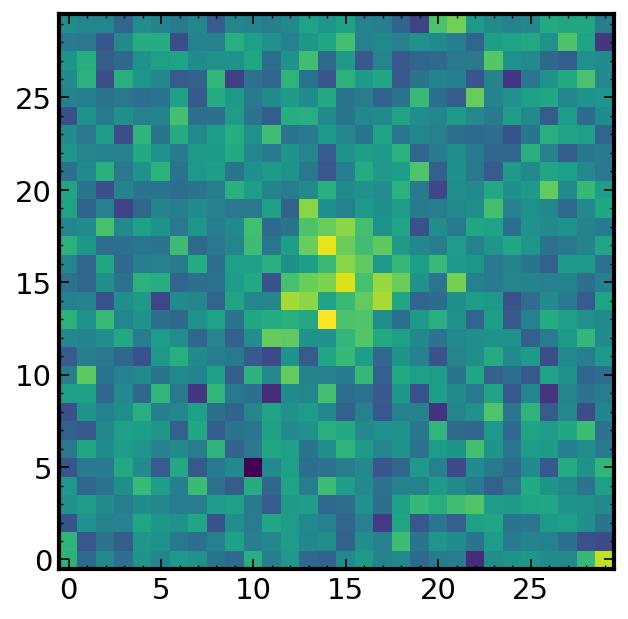

In [263]:
plt.imshow(test.data[int(p.z)-2:int(p.z)+2,:,:].sum(axis=(0)))